In [11]:
# Instal library split-folders (hanya jalankan sekali jika belum ada)
!pip install split-folders

import os
import shutil
import splitfolders

print("=== TAHAP 1: MENGGABUNGKAN DATASET (PUSPITA + KAGGLE STABIL) ===")

master_dir = 'dataset_master'
classes = ['healthy', 'leaf curl', 'leaf spot', 'powdery mildew', 'whitefly', 'yellowish']

# Hapus folder master lama agar bersih
if os.path.exists(master_dir):
    shutil.rmtree(master_dir)

for cls in classes:
    os.makedirs(os.path.join(master_dir, cls), exist_ok=True)

# Fungsi aman: menelusuri seluruh file secara rekursif tapi mencegah duplikasi nama folder
def merge_dataset_safe(source_path, source_name):
    if not os.path.exists(source_path):
        print(f"Peringatan: Folder '{source_path}' tidak ditemukan, dilewati.")
        return
    
    count = 0
    seen_files = set() # Set untuk memastikan tidak ada file yang ter-copy ganda
    
    for root, dirs, files in os.walk(source_path):
        for file in files:
            if file.lower().endswith(('.png', '.jpg', '.jpeg', '.webp')):
                parent_folder = os.path.basename(root).lower().replace('_', ' ').replace('-', ' ')
                
                matched_class = None
                if 'healthy' in parent_folder:
                    matched_class = 'healthy'
                elif 'curl' in parent_folder:
                    matched_class = 'leaf curl'
                elif 'spot' in parent_folder:
                    matched_class = 'leaf spot'
                elif 'powdery' in parent_folder or 'mildew' in parent_folder:
                    matched_class = 'powdery mildew'
                elif 'whitefly' in parent_folder or 'white fly' in parent_folder:
                    matched_class = 'whitefly'
                elif 'yellow' in parent_folder or 'yellowish' in parent_folder:
                    matched_class = 'yellowish'
                
                if matched_class:
                    src_file = os.path.join(root, file)
                    
                    # Cegah duplikasi file berdasarkan nama uniknya
                    file_signature = (file, os.path.getsize(src_file) if os.path.exists(src_file) else 0)
                    if file_signature not in seen_files:
                        seen_files.add(file_signature)
                        
                        new_filename = f"{source_name}_{os.path.basename(root)}_{file}"
                        dst_file = os.path.join(master_dir, matched_class, new_filename)
                        
                        shutil.copy(src_file, dst_file)
                        count += 1
                        
    print(f"Berhasil menyalin {count} gambar dari sumber: {source_name}")

# Jalankan penggabungan untuk Puspita dan Kaggle
merge_dataset_safe('Chili.v1i.folder (1)', 'puspita')

base_kaggle_path = 'kaggle/Chili Leaf Disease Dataset'
merge_dataset_safe(os.path.join(base_kaggle_path, 'Train'), 'kaggle_train')
merge_dataset_safe(os.path.join(base_kaggle_path, 'Validation'), 'kaggle_val')
merge_dataset_safe(os.path.join(base_kaggle_path, 'Test'), 'kaggle_test')

print("\n=== TAHAP 2: MEMBAGI DATASET (SPLIT FOLDERS) ===")

dataset_awal = 'dataset_master/'
dataset_split = 'dataset_split/'

if os.path.exists(dataset_split):
    shutil.rmtree(dataset_split)
os.makedirs(dataset_split)

splitfolders.ratio(
    dataset_awal, 
    output=dataset_split, 
    seed=42, 
    ratio=(0.7, 0.2, 0.1), 
    group_prefix=None, 
    move=False 
)

print("Pembagian dataset gabungan selesai dengan aman!")
print(f"Train : {dataset_split}train")
print(f"Val   : {dataset_split}val")
print(f"Test  : {dataset_split}test")

=== TAHAP 1: MENGGABUNGKAN DATASET (PUSPITA + KAGGLE STABIL) ===
Berhasil menyalin 1147 gambar dari sumber: puspita
Berhasil menyalin 1600 gambar dari sumber: kaggle_train
Berhasil menyalin 200 gambar dari sumber: kaggle_val
Berhasil menyalin 200 gambar dari sumber: kaggle_test

=== TAHAP 2: MEMBAGI DATASET (SPLIT FOLDERS) ===


Copying files: 3147 files [00:06, 514.61 files/s]

Pembagian dataset gabungan selesai dengan aman!
Train : dataset_split/train
Val   : dataset_split/val
Test  : dataset_split/test


In [12]:
# ==========================================
# BLOK 2: Import Library & Definisi Path
# ==========================================
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.models import Model
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout, Input
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

# Definisikan path yang mengarah langsung ke folder dataset hasil split
# (Biasanya struktur split-folders membuat subfolder train & val di dalam folder utama)
# Definisikan path yang benar sesuai struktur folder Anda
train_dir = 'Chili.v1i.folder/train'
val_dir = 'Chili.v1i.folder/valid'   # (atau 'Chili.v1i.folder/test' jika Anda pakai test untuk validasi)

# Parameter global untuk model
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
NUM_CLASSES = 6

print("Blok 2 selesai: Library berhasil dimuat dan path telah diatur!")

Blok 2 selesai: Library berhasil dimuat dan path telah diatur!


In [13]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.utils.class_weight import compute_class_weight

# Sesuaikan path agar mengarah ke folder hasil split dataset gabungan
train_dir = 'dataset_split/train'
val_dir = 'dataset_split/val'

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

# DEFINISIKAN 6 KELAS UTAMA SECARA EKSPLISIT 
# (Ini kuncinya agar TensorFlow tidak membaca folder ekstra/sampah dari Kaggle)
TARGET_CLASSES = ['healthy', 'leaf curl', 'leaf spot', 'powdery mildew', 'whitefly', 'yellowish']

# Buat Data Generator & Augmentasi
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    vertical_flip=True,
    fill_mode='nearest'
)

val_datagen = ImageDataGenerator(rescale=1./255)

train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    classes=TARGET_CLASSES,  # <-- Tambahan parameter ini agar pas 6 kelas
    shuffle=True
)

val_generator = val_datagen.flow_from_directory(
    val_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    classes=TARGET_CLASSES,  # <-- Tambahan parameter ini agar pas 6 kelas
    shuffle=False
)

# Hitung Bobot Otomatis untuk Imbalanced Dataset
if train_generator.samples > 0:
    class_weights = compute_class_weight(
        class_weight='balanced',
        classes=np.unique(train_generator.classes),
        y=train_generator.classes
    )
    class_weights_dict = dict(enumerate(class_weights))
    print("\nSukses! Gambar terbaca dan Class Weights berhasil dihitung:")
    print(class_weights_dict)
else:
    print("\nFolder masih kosong, periksa kembali nama foldernya.")

Found 2200 images belonging to 6 classes.
Found 627 images belonging to 6 classes.

Sukses! Gambar terbaca dan Class Weights berhasil dihitung:
{0: np.float64(0.912106135986733), 1: np.float64(0.842911877394636), 2: np.float64(0.8221225710014948), 3: np.float64(3.8596491228070176), 4: np.float64(0.9075907590759076), 5: np.float64(0.8771929824561403)}


In [14]:
# --- Load Base Model MobileNetV2 ---
base_model = MobileNetV2(
    weights='imagenet', 
    include_top=False, 
    input_shape=(224, 224, 3)
)

# Freeze base model agar bobot awal ImageNet tidak berubah selama training awal
base_model.trainable = False

# --- Tambahkan Custom Layers ---
inputs = Input(shape=(224, 224, 3))
x = base_model(inputs, training=False) # training=False memastikan layer BN tidak ter-update
x = GlobalAveragePooling2D()(x)
x = Dense(256, activation='relu')(x)
x = Dropout(0.5)(x)
outputs = Dense(NUM_CLASSES, activation='softmax')(x)

# Gabungkan menjadi satu model utama
model = Model(inputs, outputs)

# Tampilkan ringkasan arsitektur model
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 6)              │         1,542 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,587,462 (9.87 MB)

 Trainable params: 329,478 (1.26 MB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [15]:
# --- Kompilasi Model ---
model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# --- Definisi Callbacks ---a
# EarlyStopping: Hentikan training jika val_accuracy tidak membaik selama 10 epoch
early_stop = EarlyStopping(
    monitor='val_accuracy', 
    patience=10, 
    mode='max', 
    verbose=1,
    restore_best_weights=True
)

# ModelCheckpoint: Simpan model terbaik ke file .h5 berdasarkan val_accuracy tertinggi
checkpoint = ModelCheckpoint(
    filepath='mobilenetv2_cabai.h5', 
    monitor='val_accuracy', 
    save_best_only=True, 
    mode='max', 
    verbose=1
)

callbacks_list = [early_stop, checkpoint]

# --- Proses Pelatihan ---
EPOCHS = 30 # Anda bisa atur maks epoch, EarlyStopping akan menghentikan jika overfitting

# Contoh saat Anda melatih model
history = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=20, # atau berapapun epoch Anda
    callbacks=[early_stop, checkpoint]
)






print("Pelatihan model selesai!")

Epoch 1/20
69/69 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.6309 - loss: 1.0633
Epoch 1: val_accuracy improved from None to 0.84370, saving model to mobilenetv2_cabai.h5



Epoch 1: finished saving model to mobilenetv2_cabai.h5
69/69 ━━━━━━━━━━━━━━━━━━━━ 128s 2s/step - accuracy: 0.6309 - loss: 1.0633 - val_accuracy: 0.8437 - val_loss: 0.4785
Epoch 2/20
69/69 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.7977 - loss: 0.5909
Epoch 2: val_accuracy improved from 0.84370 to 0.86762, saving model to mobilenetv2_cabai.h5



Epoch 2: finished saving model to mobilenetv2_cabai.h5
69/69 ━━━━━━━━━━━━━━━━━━━━ 103s 1s/step - accuracy: 0.7977 - loss: 0.5909 - val_accuracy: 0.8676 - val_loss: 0.3671
Epoch 3/20
69/69 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.8364 - loss: 0.4850
Epoch 3: val_accuracy improved from 0.86762 to 0.90112, saving model to mobilenetv2_cabai.h5



Epoch 3: finished saving model to mobilenetv2_cabai.h5
69/69 ━━━━━━━━━━━━━━━━━━━━ 96s 1s/step - accuracy: 0.8364 - loss: 0.4850 - val_accuracy: 0.9011 - val_loss: 0.3126
Epoch 4/20
69/69 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.8455 - loss: 0.4643
Epoch 4: val_accuracy did not improve from 0.90112
69/69 ━━━━━━━━━━━━━━━━━━━━ 95s 1s/step - accuracy: 0.8455 - loss: 0.4643 - val_accuracy: 0.8852 - val_loss: 0.3143
Epoch 5/20
69/69 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.8605 - loss: 0.3938
Epoch 5: val_accuracy did not improve from 0.90112
69/69 ━━━━━━━━━━━━━━━━━━━━ 94s 1s/step - accuracy: 0.8605 - loss: 0.3938 - val_accuracy: 0.9011 - val_loss: 0.2774
Epoch 6/20
69/69 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.8586 - loss: 0.4020
Epoch 6: val_accuracy did not improve from 0.90112
69/69 ━━━━━━━━━━━━━━━━━━━━ 89s 1s/step - accuracy: 0.8586 - loss: 0.4020 - val_accuracy: 0.9011 - val_loss: 0.2837
Epoch 7/20
69/69 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.8714 - loss: 0.3623


Epoch 9: finished saving model to mobilenetv2_cabai.h5
69/69 ━━━━━━━━━━━━━━━━━━━━ 85s 1s/step - accuracy: 0.8750 - loss: 0.3489 - val_accuracy: 0.9155 - val_loss: 0.2593
Epoch 10/20
69/69 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.8855 - loss: 0.3077
Epoch 10: val_accuracy improved from 0.91547 to 0.92185, saving model to mobilenetv2_cabai.h5



Epoch 10: finished saving model to mobilenetv2_cabai.h5
69/69 ━━━━━━━━━━━━━━━━━━━━ 89s 1s/step - accuracy: 0.8855 - loss: 0.3077 - val_accuracy: 0.9219 - val_loss: 0.2488
Epoch 11/20
69/69 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.8923 - loss: 0.3066
Epoch 11: val_accuracy improved from 0.92185 to 0.92823, saving model to mobilenetv2_cabai.h5



Epoch 11: finished saving model to mobilenetv2_cabai.h5
69/69 ━━━━━━━━━━━━━━━━━━━━ 86s 1s/step - accuracy: 0.8923 - loss: 0.3066 - val_accuracy: 0.9282 - val_loss: 0.2496
Epoch 12/20
69/69 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.8964 - loss: 0.3130
Epoch 12: val_accuracy did not improve from 0.92823
69/69 ━━━━━━━━━━━━━━━━━━━━ 85s 1s/step - accuracy: 0.8964 - loss: 0.3130 - val_accuracy: 0.9266 - val_loss: 0.2320
Epoch 13/20
69/69 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9064 - loss: 0.2675
Epoch 13: val_accuracy did not improve from 0.92823
69/69 ━━━━━━━━━━━━━━━━━━━━ 84s 1s/step - accuracy: 0.9064 - loss: 0.2675 - val_accuracy: 0.9155 - val_loss: 0.2597
Epoch 14/20
69/69 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9005 - loss: 0.2700
Epoch 14: val_accuracy did not improve from 0.92823
69/69 ━━━━━━━━━━━━━━━━━━━━ 87s 1s/step - accuracy: 0.9005 - loss: 0.2700 - val_accuracy: 0.9219 - val_loss: 0.2131
Epoch 15/20
69/69 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9000 - loss


Epoch 16: finished saving model to mobilenetv2_cabai.h5
69/69 ━━━━━━━━━━━━━━━━━━━━ 102s 1s/step - accuracy: 0.8986 - loss: 0.2806 - val_accuracy: 0.9362 - val_loss: 0.2013
Epoch 17/20
69/69 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9127 - loss: 0.2602
Epoch 17: val_accuracy did not improve from 0.93620
69/69 ━━━━━━━━━━━━━━━━━━━━ 100s 1s/step - accuracy: 0.9127 - loss: 0.2602 - val_accuracy: 0.9282 - val_loss: 0.2164
Epoch 18/20
69/69 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9141 - loss: 0.2518
Epoch 18: val_accuracy did not improve from 0.93620
69/69 ━━━━━━━━━━━━━━━━━━━━ 88s 1s/step - accuracy: 0.9141 - loss: 0.2518 - val_accuracy: 0.9314 - val_loss: 0.2132
Epoch 19/20
69/69 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9114 - loss: 0.2421
Epoch 19: val_accuracy did not improve from 0.93620
69/69 ━━━━━━━━━━━━━━━━━━━━ 91s 1s/step - accuracy: 0.9114 - loss: 0.2421 - val_accuracy: 0.9250 - val_loss: 0.2383
Epoch 20/20
69/69 ━━━━━━━━━━━━━━━━━━━━ 0s 25s/step - accuracy: 0.9227 - l

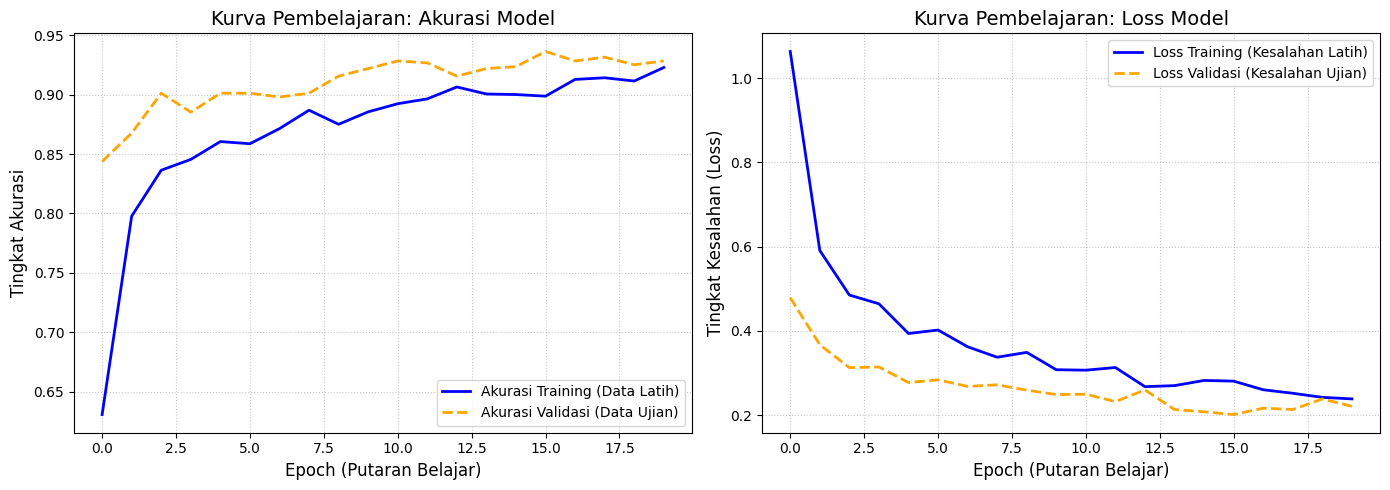

In [16]:
import matplotlib.pyplot as plt

# Mengambil data dari variabel 'history' hasil training
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']
epochs_range = range(len(acc))

# Membuat figur berukuran 14x5 inci
plt.figure(figsize=(14, 5))

# Grafik 1: Akurasi (Buktikan model semakin pintar)
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Akurasi Training (Data Latih)', color='blue', linewidth=2)
plt.plot(epochs_range, val_acc, label='Akurasi Validasi (Data Ujian)', color='orange', linestyle='--', linewidth=2)
plt.title('Kurva Pembelajaran: Akurasi Model', fontsize=14)
plt.xlabel('Epoch (Putaran Belajar)', fontsize=12)
plt.ylabel('Tingkat Akurasi', fontsize=12)
plt.legend(loc='lower right')
plt.grid(True, linestyle=':', alpha=0.7)

# Grafik 2: Loss (Buktikan tingkat kesalahan menurun)
plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Loss Training (Kesalahan Latih)', color='blue', linewidth=2)
plt.plot(epochs_range, val_loss, label='Loss Validasi (Kesalahan Ujian)', color='orange', linestyle='--', linewidth=2)
plt.title('Kurva Pembelajaran: Loss Model', fontsize=14)
plt.xlabel('Epoch (Putaran Belajar)', fontsize=12)
plt.ylabel('Tingkat Kesalahan (Loss)', fontsize=12)
plt.legend(loc='upper right')
plt.grid(True, linestyle=':', alpha=0.7)

plt.tight_layout()
plt.show()

In [17]:
# --- Konversi H5 ke TFLite ---
# Load model terbaik yang sudah disimpan oleh ModelCheckpoint
model_h5_path = 'mobilenetv2_cabai.h5'
tflite_model_path = 'mobilenetv2_cabai.tflite'

print(f"Memuat model terbaik dari: {model_h5_path}")
best_model = tf.keras.models.load_model(model_h5_path)

# Inisialisasi converter TFLite
converter = tf.lite.TFLiteConverter.from_keras_model(best_model)

# Opsional: Terapkan optimasi (quantization) untuk memperkecil ukuran file model (default: float16)
converter.optimizations = [tf.lite.Optimize.DEFAULT]

# Lakukan konversi
print("Melakukan konversi ke TFLite...")
tflite_model = converter.convert()

# Simpan model TFLite ke disk
with open(tflite_model_path, 'wb') as f:
    f.write(tflite_model)


print(f"Konversi selesai! Model TFLite disimpan di: {tflite_model_path}")

Memuat model terbaik dari: mobilenetv2_cabai.h5


Melakukan konversi ke TFLite...
INFO:tensorflow:Assets written to: C:\Users\Asus\AppData\Local\Temp\tmpo2jzsfzu\assets


INFO:tensorflow:Assets written to: C:\Users\Asus\AppData\Local\Temp\tmpo2jzsfzu\assets


Saved artifact at 'C:\Users\Asus\AppData\Local\Temp\tmpo2jzsfzu'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='input_layer_3')
Output Type:
  TensorSpec(shape=(None, 6), dtype=tf.float32, name=None)
Captures:
  2098198715792: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2098198717904: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2098198715216: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2098198718096: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2098198717328: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2098198713872: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2098198711952: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2098198717520: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2098198714640: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2098198719056: TensorSpec(shape=(), dtype=tf.resource, name=None)
  20981

Menghitung Prediksi untuk Transparansi Evaluasi...
20/20 ━━━━━━━━━━━━━━━━━━━━ 14s 639ms/step

--- CLASSIFICATION REPORT ---
Transparansi nilai Precision, Recall, dan F1-Score tiap penyakit:
                precision    recall  f1-score   support

       healthy       0.93      0.98      0.95       115
     leaf curl       0.97      0.94      0.95       124
     leaf spot       0.92      0.94      0.93       127
powdery mildew       0.86      0.93      0.89        27
      whitefly       0.97      0.90      0.93       115
     yellowish       0.92      0.93      0.93       119

      accuracy                           0.94       627
     macro avg       0.93      0.93      0.93       627
  weighted avg       0.94      0.94      0.94       627



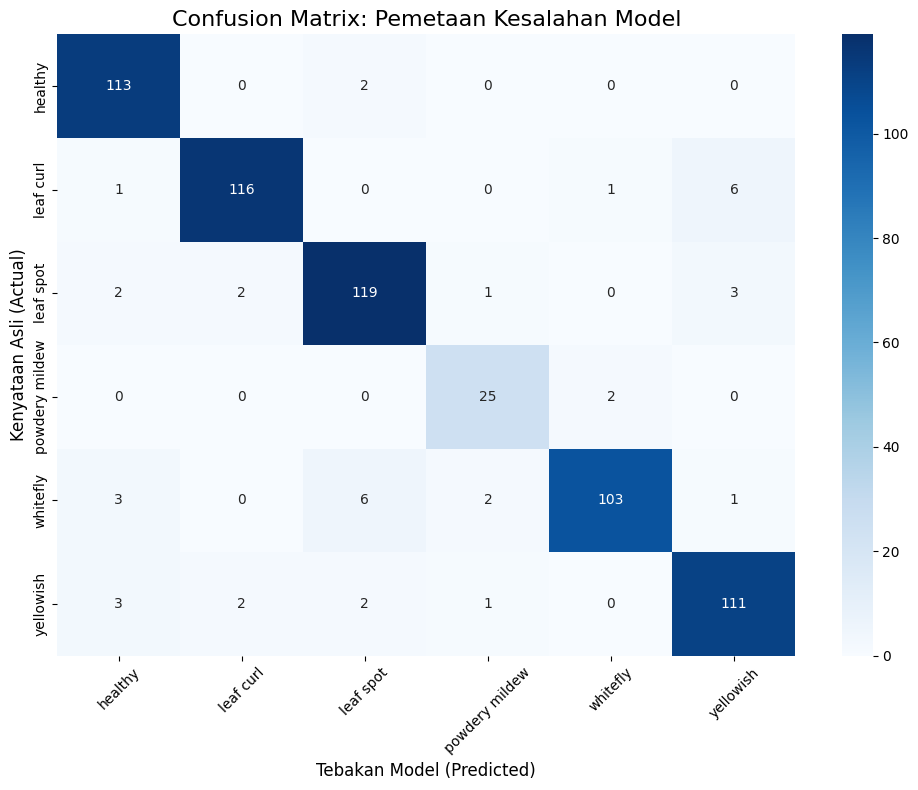

In [18]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

print("Menghitung Prediksi untuk Transparansi Evaluasi...")
# Menggunakan val_generator (pastikan saat inisialisasi val_generator, shuffle=False)
# Agar urutan data yang diprediksi sama dengan urutan label aslinya
predictions = model.predict(val_generator)
y_pred = np.argmax(predictions, axis=1) 
y_true = val_generator.classes          

# Mengambil nama-nama penyakit (6 Kelas)
class_names = list(val_generator.class_indices.keys())

# --- MENCETAK LAPORAN DETAIL ---
print("\n--- CLASSIFICATION REPORT ---")
print("Transparansi nilai Precision, Recall, dan F1-Score tiap penyakit:")
print(classification_report(y_true, y_pred, target_names=class_names))

# --- MENGGAMBAR CONFUSION MATRIX ---
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix: Pemetaan Kesalahan Model', fontsize=16)
plt.xlabel('Tebakan Model (Predicted)', fontsize=12)
plt.ylabel('Kenyataan Asli (Actual)', fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [3]:
#Logika Confidence Threshold / Filter Penolakan


import numpy as np
from tensorflow.keras.preprocessing import image

# 1. Definisikan 6 kelas utama penyakit daun cabai yang valid
class_names = ['Healthy', 'Leaf Curl', 'Leaf Spot', 'Powdery Mildew', 'Whitefly', 'Yellowish']

def prediksi_dan_validasi_citra(img_path, model, threshold=0.70):
    """
    Fungsi untuk memprediksi citra daun cabai sekaligus menolak 
    gambar asing / bukan daun cabai berdasarkan Threshold akurasi.
    """
    # Load dan sesuaikan ukuran citra dengan input model (224x224)
    img = image.load_img(img_path, target_size=(224, 224))
    x = image.img_to_array(img)
    x = np.expand_dims(x, axis=0)
    x = x / 255.0  # Normalisasi piksel
    
    # Lakukan prediksi menggunakan model yang sudah ada
    predictions = model.predict(x)
    max_probability = np.max(predictions)        # Ambil nilai probabilitas tertinggi
    predicted_class_idx = np.argmax(predictions) # Ambil indeks kelas prediksi
    
    print(f"\n--- HASIL ANALISIS CITRA ---")
    print(f"Skor Keyakinan Tertinggi: {max_probability * 100:.2f}%")
    
    # 2. Logika Validasi Threshold (Filter Gambar Asing)
    if max_probability < threshold:
        print("❌ STATUS: GAMBAR DITOLAK!")
        print("Pesan Sistem: Objek tidak dikenali sebagai daun cabai atau gambar terlalu buram.")
        print("Saran: Mohon unggah foto daun cabai yang valid dan jelas.")
        return None, None
    else:
        detected_class = class_names[predicted_class_idx]
        print("✅ STATUS: GAMBAR DITERIMA")
        print(f"Jenis Penyakit Terdeteksi: {detected_class}")
        return detected_class, max_probability

# --- Contoh Cara Menggunakannya di Aplikasi / Testing ---
# Ganti path di bawah dengan path gambar uji yang ingin di-upload
# path_gambar_uji = 'path/ke/gambar_daun_atau_benda_lain.jpg'

# Memanggil fungsi validasi menggunakan model akhir (misal: model yang sudah di-load)
# hasil_kelas, tingkat_akurasi = prediksi_dan_validasi_citra(path_gambar_uji, model, threshold=0.70)

In [2]:
import os
from collections import defaultdict

# Sesuaikan path induknya jika folder ini ada di dalam subfolder tertentu
BASE_DIR = "."  # atau misal r"C:\project semester 5\..."

DS1_DIR = os.path.join(BASE_DIR, "Chili.v1i.folder (1)")
DS2_DIR = os.path.join(BASE_DIR, "kaggle")
MASTER_DIR = os.path.join(BASE_DIR, "dataset_master")
SPLIT_DIR = os.path.join(BASE_DIR, "dataset_split")

EXTS = (".jpg", ".jpeg", ".png", ".webp", ".bmp")
CLASSES = [
    "healthy",
    "leaf curl",
    "leaf spot",
    "powdery mildew",
    "whitefly",
    "yellowish",
]

def norm_label(name: str) -> str:
    s = name.strip().lower().replace("_", " ").replace("-", " ")
    mapping = {
        "healthy": "healthy",
        "daun sehat": "healthy",
        "leaf curl": "leaf curl",
        "keriting daun": "leaf curl",
        "leaf spot": "leaf spot",
        "bercak daun": "leaf spot",
        "powdery mildew": "powdery mildew",
        "embun tepung": "powdery mildew",
        "whitefly": "whitefly",
        "kutu kebul": "whitefly",
        "yellowish": "yellowish",
        "virus kuning": "yellowish",
        "daun kekuningan": "yellowish",
    }
    return mapping.get(s, s)

def count_by_class(folder_path: str) -> dict:
    counts = defaultdict(int)
    if not os.path.exists(folder_path):
        print(f"[INFO] Tidak ada: {folder_path}")
        return counts
    for root, _, files in os.walk(folder_path):
        imgs = [f for f in files if f.lower().endswith(EXTS)]
        if imgs:
            lbl = norm_label(os.path.basename(root))
            counts[lbl] += len(imgs)
    return counts

def count_splits(split_root: str) -> dict:
    out = {"train": defaultdict(int), "val": defaultdict(int), "test": defaultdict(int)}
    if not os.path.exists(split_root):
        print(f"[INFO] Tidak ada: {split_root}")
        return out
    for sub in os.listdir(split_root):
        sub_path = os.path.join(split_root, sub)
        if not os.path.isdir(sub_path):
            continue
        k = sub.strip().lower()
        key = "train" if "train" in k else ("val" if "val" in k else ("test" if "test" in k else None))
        if not key:
            continue
        for root, _, files in os.walk(sub_path):
            imgs = [f for f in files if f.lower().endswith(EXTS)]
            if imgs:
                lbl = norm_label(os.path.basename(root))
                out[key][lbl] += len(imgs)
    return out

c_chili = count_by_class(DS1_DIR)
c_kaggle = count_by_class(DS2_DIR)
c_master = count_by_class(MASTER_DIR)
c_split = count_splits(SPLIT_DIR)

labels = list(dict.fromkeys(
    CLASSES + list(c_chili.keys()) + list(c_kaggle.keys()) + list(c_master.keys())
))

print("=" * 112)
print(f"{'Kelas':<18} | {'Chili (DS1)':>11} | {'Kaggle (DS2)':>12} | {'Master':>8} | {'Train':>7} | {'Val':>7} | {'Test':>7} | {'Rasio T:V:T'}")
print("=" * 112)

t1 = t2 = tm = ttr = tva = tte = 0
for lbl in labels:
    v1 = c_chili.get(lbl, 0)
    v2 = c_kaggle.get(lbl, 0)
    vm = c_master.get(lbl, 0)
    tr = c_split["train"].get(lbl, 0)
    va = c_split["val"].get(lbl, 0)
    te = c_split["test"].get(lbl, 0)
    sub_s = tr + va + te

    t1 += v1
    t2 += v2
    tm += vm
    ttr += tr
    tva += va
    tte += te

    rasio = f"{round(tr/sub_s*100)}:{round(va/sub_s*100)}:{round(te/sub_s*100)}%" if sub_s > 0 else "-"
    if any(x > 0 for x in [v1, v2, vm, tr, va, te]):
        print(f"{lbl:<18} | {v1:>11} | {v2:>12} | {vm:>8} | {tr:>7} | {va:>7} | {te:>7} | {rasio}")

tot_s = ttr + tva + tte
tot_rasio = f"{round(ttr/tot_s*100)}:{round(tva/tot_s*100)}:{round(tte/tot_s*100)}%" if tot_s > 0 else "-"
print("=" * 112)
print(f"{'TOTAL':<18} | {t1:>11} | {t2:>12} | {tm:>8} | {ttr:>7} | {tva:>7} | {tte:>7} | {tot_rasio}")
print("=" * 112)

Kelas              | Chili (DS1) | Kaggle (DS2) |   Master |   Train |     Val |    Test | Rasio T:V:T
healthy            |         175 |          400 |      575 |     402 |     115 |      58 | 70:20:10%
leaf curl          |         222 |            0 |      622 |     435 |     124 |      63 | 70:20:10%
leaf spot          |         238 |            0 |      638 |     446 |     127 |      65 | 70:20:10%
powdery mildew     |         136 |            0 |      136 |      95 |      27 |      14 | 70:20:10%
whitefly           |         178 |          400 |      578 |     404 |     115 |      59 | 70:20:10%
yellowish          |         198 |           80 |      598 |     418 |     119 |      61 | 70:20:10%
curl               |           0 |          400 |        0 |       0 |       0 |       0 | -
spot               |           0 |          400 |        0 |       0 |       0 |       0 | -
yellowfish         |           0 |          320 |        0 |       0 |       0 |       0 | -
TOTAL       

Found 320 images belonging to 6 classes.
10/10 ━━━━━━━━━━━━━━━━━━━━ 14s 1s/step
Total Data Testing : 320 citra
Test Accuracy      : 92.81%
Precision (Macro)  : 92.75%
Recall (Macro)     : 90.06%
F1-Score (Macro)   : 91.17%

--- CLASSIFICATION REPORT (TESTING SET) ---
                precision    recall  f1-score   support

       healthy     0.9167    0.9483    0.9322        58
     leaf curl     0.9062    0.9206    0.9134        63
     leaf spot     0.8986    0.9538    0.9254        65
powdery mildew     0.9091    0.7143    0.8000        14
      whitefly     1.0000    0.9322    0.9649        59
     yellowish     0.9344    0.9344    0.9344        61

      accuracy                         0.9281       320
     macro avg     0.9275    0.9006    0.9117       320
  weighted avg     0.9294    0.9281    0.9278       320



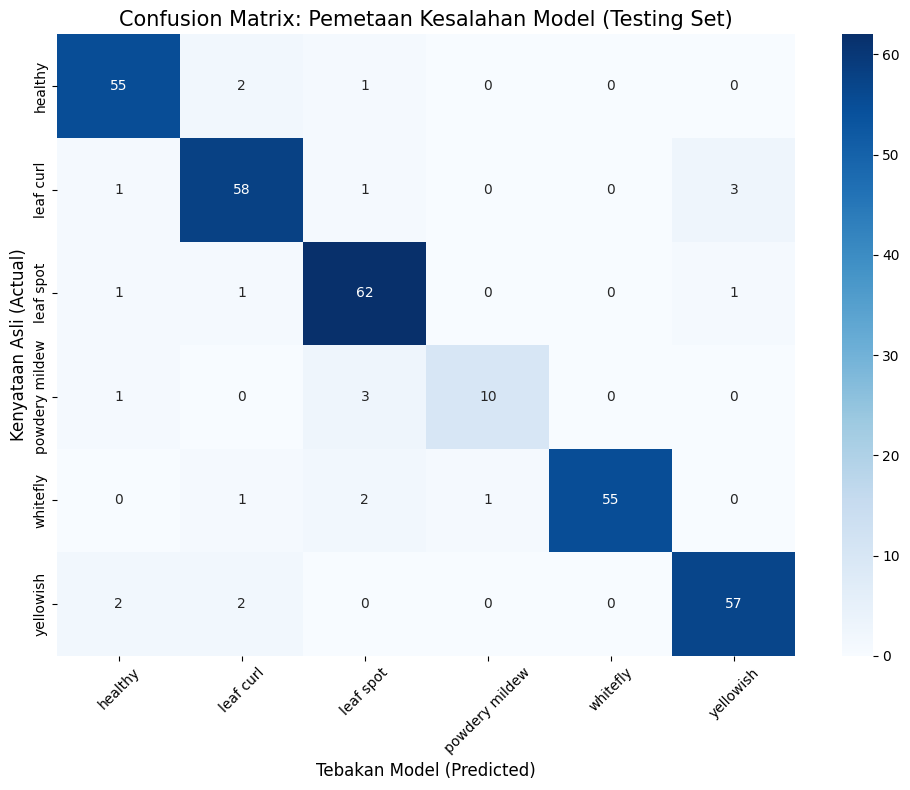

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, precision_score, recall_score, f1_score

# 1. Load model yang sudah disimpan (tidak perlu training ulang)
model = tf.keras.models.load_model("mobilenetv2_cabai.h5")

# 2. Siapkan test_generator dari folder dataset_split/test (shuffle=False wajib!)
test_datagen = ImageDataGenerator(rescale=1./255)
test_generator = test_datagen.flow_from_directory(
    "dataset_split/test",
    target_size=(224, 224),
    batch_size=32,
    class_mode="categorical",
    shuffle=False
)

# 3. Prediksi pada 320 data testing
predictions = model.predict(test_generator)
y_pred = np.argmax(predictions, axis=1)
y_true = test_generator.classes
class_names = list(test_generator.class_indices.keys())

# 4. Cetak metrik persis 2 desimal (untuk Abstrak, Tabel, & Kesimpulan)
acc = accuracy_score(y_true, y_pred) * 100
prec_macro = precision_score(y_true, y_pred, average="macro") * 100
rec_macro = recall_score(y_true, y_pred, average="macro") * 100
f1_macro = f1_score(y_true, y_pred, average="macro") * 100

print("=" * 60)
print(f"Total Data Testing : {len(y_true)} citra")
print(f"Test Accuracy      : {acc:.2f}%")
print(f"Precision (Macro)  : {prec_macro:.2f}%")
print(f"Recall (Macro)     : {rec_macro:.2f}%")
print(f"F1-Score (Macro)   : {f1_macro:.2f}%")
print("=" * 60)

print("\n--- CLASSIFICATION REPORT (TESTING SET) ---")
print(classification_report(y_true, y_pred, target_names=class_names, digits=4))

# 5. Gambar Confusion Matrix Testing Set
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.title("Confusion Matrix: Pemetaan Kesalahan Model (Testing Set)", fontsize=15)
plt.xlabel("Tebakan Model (Predicted)", fontsize=12)
plt.ylabel("Kenyataan Asli (Actual)", fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("confusion_matrix_testing.png", dpi=300)
plt.show()